In [14]:
#
#
#

import arslabrobotics as ar

import numpy as np
import scipy

data = np.loadtxt("cart_data.txt")
(rows, _) = data.shape

delta_t = 0.01

arx = ar.identification.ARXSolver(data, 3, 0)
(a, b) = arx.solve()

print("a,b:", a,b)
print()

# Discrete system mnodel
system = ar.identification.ARXModel(a, b)
(A, B, C) = system.state_space()

# resize the matrices in order to add position as state variable
A = np.hstack( (A, np.zeros( (3,1) ) ) )
A = np.vstack( (A, np.zeros( (1,4) ) ) ) 
B = np.vstack( (B, [0]) )

A[3,0] = delta_t
A[3,3] = 1.0


print("State Matrix:\n", A)
print("Input Matrix:\n", B)


a,b: [-0.32458049755043067, -0.3273264819831701, -0.330097404696547] [0.019995128633168435]

State Matrix:
 [[0.3245805  0.32732648 0.3300974  0.        ]
 [1.         0.         0.         0.        ]
 [0.         1.         0.         0.        ]
 [0.01       0.         0.         1.        ]]
Input Matrix:
 [[0.01999513]
 [0.        ]
 [0.        ]
 [0.        ]]


In [25]:

# speed has no cost, only position
Q = np.zeros( (4,4), dtype=np.float32)
Q[3,3]=1

R = np.eye( 1, dtype=np.float32) * 0.01

P = scipy.linalg.solve_discrete_are(A, B, Q, R)
K = np.linalg.inv(R + B.T @ P @ B) @ B.T @ P @ A

print("Optimal Gain:", K)


Optimal Gain: [[1.83468703 1.17359323 0.59477993 9.81820843]]


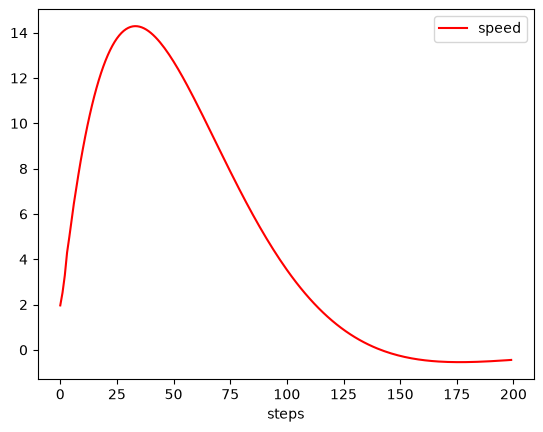

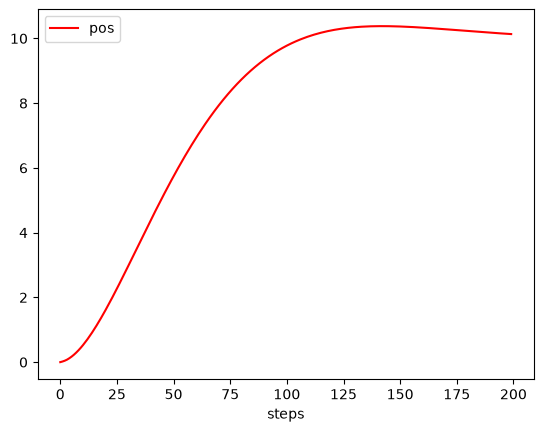

In [27]:

x = np.array([ 0., 0., 0., 0.0])

set_point = np.array([0., 0., 0., 10.0])

x_t = x - set_point

dps = ar.data.DataPlotter()
dps.set_x("steps")
dps.add_y("speed", "speed")

dpp = ar.data.DataPlotter()
dpp.set_x("steps")
dpp.add_y("pos", "pos")

for t in range(0,200):
    u = - K @ x_t
    x_t = A @ x_t + B @ u
    x = x_t + set_point
    dps.append_x(t)
    dps.append_y("speed", x[0])
    dpp.append_x(t)
    dpp.append_y("pos", x[3])

dps.plot()
dpp.plot()
